In [ ]:
def simple_irr(tvpi, years):
    return tvpi**(1/years)-1

print(simple_irr(2,5))
print(simple_irr(2,12))

0.1486983549970351
0.05946309435929531


In [3]:
import numpy as np

years = np.arange(1, 13)                  # years 1 to 12
calls = np.where(years <= 5, -24, 0)      # LP pays in, years 1-5
dists = np.where(years >= 6, 235.2 / 7, 0)  # exits pay out, years 6-12

net_flow = calls + dists                  # cash flow for the LP each year
cumulative = np.cumsum(net_flow)          # running balance = the J-curve

for y, c in zip(years, cumulative):
    print("Year", y, "| cumulative:", round(c, 1))

Year 1 | cumulative: -24.0
Year 2 | cumulative: -48.0
Year 3 | cumulative: -72.0
Year 4 | cumulative: -96.0
Year 5 | cumulative: -120.0
Year 6 | cumulative: -86.4
Year 7 | cumulative: -52.8
Year 8 | cumulative: -19.2
Year 9 | cumulative: 14.4
Year 10 | cumulative: 48.0
Year 11 | cumulative: 81.6
Year 12 | cumulative: 115.2


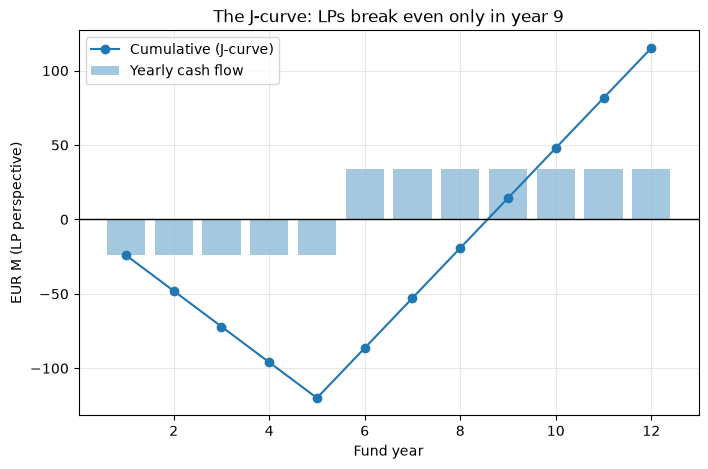

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.bar(years, net_flow, alpha=0.4, label="Yearly cash flow")
plt.plot(years, cumulative, marker="o", label="Cumulative (J-curve)")
plt.axhline(0, color="black", linewidth=1)
plt.xlabel("Fund year")
plt.ylabel("EUR M (LP perspective)")
plt.title("The J-curve: LPs break even only in year 9")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("../results/phase4_j_curve.png", dpi=150, bbox_inches="tight")
plt.show()

In [8]:
import numpy_financial as npf

print("IRR from cash flows:", npf.irr(net_flow).__round__(3))
print("Simple IRR (1.96x over 12 years):", round(1.96 ** (1/12) - 1, 3))

IRR from cash flows: 0.121
Simple IRR (1.96x over 12 years): 0.058


## What this means

**Timing matters.** TVPI says how much LPs get back, not when. Two funds with the same 2x TVPI can have very different annual returns: 2x in 5 years is about 14.9% a year, 2x in 12 years only about 5.9%.

**Our average fund.** We take the average net TVPI from phase 3 (1.96x) and assume LPs pay in EUR 24M a year in years 1-5, while exits return EUR 235.2M in equal parts in years 6-12.

- **J-curve:** the LP balance falls to -EUR 120M in year 5 and turns positive only in year 9.
- **IRR:** 12.1% from the cash flows, versus 5.8% if all capital were locked up for the full 12 years. Capital is called gradually and returned gradually, so each euro is invested for about 6 years on average.
- **DPI** (cash actually returned divided by paid-in capital) is zero until year 6. Until then, the fund's value exists only on paper.

**Limitation.** The timing is a simple assumption. IRR is very sensitive to it: later exits would lower the IRR while leaving TVPI unchanged. That is why LPs always read TVPI, IRR and DPI together.